# Hangman strategy explorer

Compare the hangman strategies from `strategy.py`, `optimal.py` and `winprob.py`
on one word length under a chosen word distribution. Pick a `LENGTH`, a
`WEIGHTING` (how likely each word is to be the secret word) and a `STRATEGY`,
then re-run the rest: the opener, hardest words, per-guess tree, and how the
headline number scales with length all follow your choice.

Reminders: a *miss* is a wrong letter guess. `optimal`/`winprob` replay the
solvers' committed trees, so they only cover length/weighting combinations that
have already been solved -- others report cleanly instead of erroring.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'strategy.py').exists():
            return c
    raise FileNotFoundError('Could not find strategy.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import strategy
import strategy_view as sview
import wordlist

pd.set_option('display.max_rows', 200)   # show up to 200 rows before pandas truncates to a head/tail preview

print(f'imported strategy + strategy_view from {math_dir}')

imported strategy + strategy_view from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Pick length, distribution, and strategy

Change `LENGTH`, `WEIGHTING`, `STRATEGY` (and `BUDGET`, for winprob;
`FILL_CAPPED`, for optimal), then re-run the rest.

`WEIGHTING` -- how likely each word is to be the secret word:
- `"uniform"` -- every word equally likely.
- `"zipf"` -- real English frequency (common words weigh more).
- `"greedy"` / `"best_opener"` -- the adversarial word-setter from `freq_search.py`
  (per-(letter,pattern) multipliers), tuned to make that guesser work hardest.
- `"greedy_word"` / `"best_opener_word"` -- the newer *per-word* frequency adversary.

`STRATEGY` -- the guesser:
- `"greedy"` -- guess the highest combined-frequency un-guessed letter (live, any weighting).
- `"greedy_best"` -- force the best first letter, then greedy (live, any weighting).
- `"optimal"` -- minimise expected misses (replays `data/shared/optimal/`).
- `"winprob"` -- maximise P(win within `BUDGET` misses) (replays `data/shared/winprob/`).

`FILL_CAPPED` (optimal only) -- when an optimal solve has **not converged**, its
committed tree truncates the hardest branches at the miss cap (leaves marked
*capped*). With `FILL_CAPPED=True` (default) those branches are finished with
**greedy** -- optimal above the cap, greedy below -- so every word resolves and the
headline `avg_misses` is the *greedy-completed upper bound* on the true optimum
(`summary()['greedy_finished']` counts the completed words). With
`FILL_CAPPED=False` the capped words stay unresolved and the headline averages only
the fully-optimal words (a lower, optimistic partial). Converged solves ignore this
flag (they have no capped branches).

`make_strategy` returns one uniform `sv` that every cell below uses. `optimal`
and `winprob` exist only for solved length/weighting combos; when one is missing,
`sv.available` is `False` and `sv.note` says what to run -- the cells skip cleanly.

In [40]:
LENGTH    = 5           # <-- word length
WEIGHTING = "best_opener"   # <-- uniform, zipf, greedy, best_opener, greedy_word, best_opener_word
STRATEGY  = "greedy"    # <-- greedy, greedy_best, optimal, winprob
BUDGET    = None         # <-- winprob only: miss budget k (None = most permissive solved)
FILL_CAPPED = True       # <-- optimal only: finish cap-truncated branches with greedy (see note)

g  = strategy.GreedyGame(LENGTH)
sv = sview.make_strategy(STRATEGY, LENGTH, weighting=WEIGHTING, budget=BUDGET,
                         fill_capped=FILL_CAPPED, game=g)

print(f'{g.N:,} words of length {LENGTH}  (zipf >= {wordlist.DEFAULT_ZIPF})')
print(f'weighting: {WEIGHTING}   strategy: {sv.label}')
if not sv.available:
    print(f'\n!! not available: {sv.note}')
else:
    print(f'opener: {sv.opener()!r}')
    hv = sv.headline_value()
    print(f'{sv.headline_label()}: ' + (f'{hv:.4f}' if hv is not None else 'n/a'))
    for k, v in sv.summary().items():
        print(f'  {k}: {v}')
    if sv.note:
        print(f'note: {sv.note}')

3,495 words of length 5  (zipf >= 2.5)
weighting: best_opener   strategy: greedy
opener: 's'
avg misses: 5.3969
  opener: s
  avg_misses: 5.39688059651542


## Best opening letters

Expected misses if each letter is forced as the first guess and the guesser plays
on; the dashed line marks the best (its own opener). This forced-opener sweep is
greedy-family only -- for `optimal`/`winprob` it would need a re-solve per opener
(not cached), so those print a short note instead.

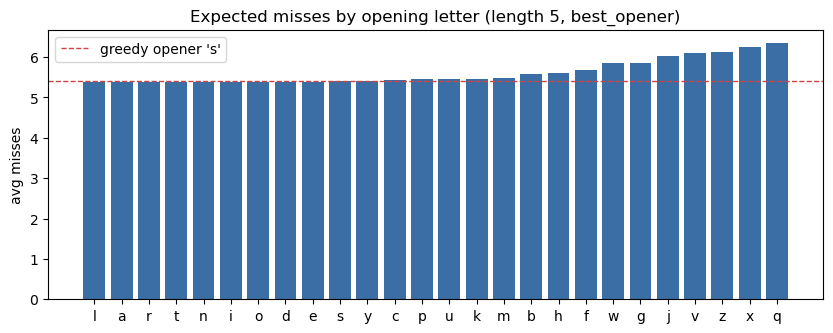

,avg_misses
first_letter,
l,5.379164
a,5.379165
r,5.379168
t,5.379173
n,5.379224
i,5.379256
o,5.379529
d,5.389776
e,5.391926


In [41]:
by_letter = sv.misses_by_starting_letter() if sv.available else None
if by_letter is None:
    print(f'{sv.label}: forced-opener sweep is greedy-family only.')
    if sv.available:
        print(f'(this strategy opens with {sv.opener()!r})')
else:
    mb = pd.Series(by_letter, name='avg_misses'); mb.index.name = 'first_letter'
    op = sv.opener()
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(mb.index, mb.values, color='#3b6ea5')
    ax.axhline(mb[op], color='#cc4444', ls='--', lw=1, label=f'{sv.label} opener {op!r}')
    ax.set_ylabel('avg misses')
    ax.set_title(f'Expected misses by opening letter (length {LENGTH}, {WEIGHTING})')
    ax.legend(); plt.show()
    display(mb.to_frame())

## Per-word difficulty

How many misses the strategy makes on each word, and the distribution. Words the
strategy leaves *unresolved* -- `optimal` words capped past the solved depth, or
`winprob` words that can't be won within the budget -- have no finite miss count
and are tallied separately (they sort to the top of the hardest list).

solved with 0 misses: 7 words
max misses: 14   mean (resolved): 6.731


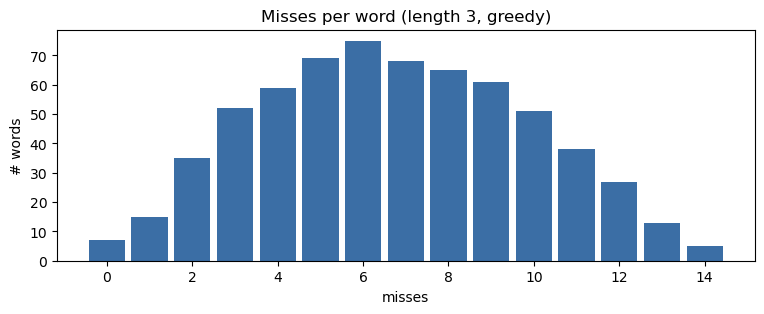

hardest words:


,word,misses
0,joy,14.0
1,you,14.0
2,say,14.0
3,vex,14.0
4,lav,14.0
5,moi,13.0
6,yet,13.0
7,wig,13.0
8,ray,13.0
9,wot,13.0


In [4]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    status = sv.per_word_status()
    resolved = pwm[~np.isnan(pwm)]
    n_unres = int(np.isnan(pwm).sum())
    words = pd.DataFrame({'word': g.words, 'misses': pwm})

    print(f'solved with 0 misses: {int((resolved == 0).sum()):,} words')
    hi = int(resolved.max()) if resolved.size else 0
    print(f'max misses: {hi}   mean (resolved): {resolved.mean():.3f}')
    if n_unres:
        kind = 'capped' if sv.kind == 'optimal' else 'lost (over budget)'
        print(f'unresolved ({kind}): {n_unres:,} words')
    n_greedy = int((status == 3).sum())
    if n_greedy:
        print(f'greedy-completed (capped branch finished with greedy): {n_greedy:,} words')

    fig, ax = plt.subplots(figsize=(9, 3))
    if resolved.size:
        ax.hist(resolved, bins=range(0, hi + 2), color='#3b6ea5', align='left', rwidth=0.85)
    ax.set_xlabel('misses'); ax.set_ylabel('# words')
    ax.set_title(f'Misses per word (length {LENGTH}, {sv.label})')
    plt.show()

    print('hardest words:')
    display(words.sort_values('misses', ascending=False, na_position='first')
                 .head(12).reset_index(drop=True))

## Trace one word

The actual guess sequence for a word under the current strategy: each guess and
whether it hit. Defaults to the hardest resolved word; set `WORD` yourself to
trace another.

In [5]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    WORD = g.words[int(np.argsort(np.where(np.isnan(pwm), -1.0, pwm))[-1])]  # hardest resolved
    # WORD = 'bench'   # <-- or pick your own

    hits = sv.trace(WORD)
    n_miss = sum(1 for _, hit in hits if not hit)
    print(f'{WORD!r}: {n_miss} misses  ({sv.label})')
    for letter, hit in hits:
        print(f'  {letter}  ' + ('hit ' if hit else 'MISS'))
    if not hits:
        print('  (the strategy leaves this word unresolved)')

'joy': 14 misses  (greedy)
  a  MISS
  o  hit 
  t  MISS
  b  MISS
  d  MISS
  w  MISS
  p  MISS
  n  MISS
  c  MISS
  s  MISS
  f  MISS
  g  MISS
  e  MISS
  l  MISS
  m  MISS
  y  hit 
  j  hit 


## Inspect a tree node

Give a board (revealed letters + `_` blanks, e.g. `"b_ll_"`) and the missed
letters; `show_state` finds that node in the current strategy's tree: the
candidates remaining, the next guess, and every outcome it can produce. States
the strategy never reaches are flagged. A hit reveals **all** positions of a
letter, so put every occurrence of a revealed letter on the board.

In [6]:
_wf = sv.word_freq() if sv.available else None
POSITIVE = {g.words[i] for i in range(g.N) if _wf[i] > 0} if _wf is not None else set()

def _keep(words):
    """Drop words that weigh 0 under the current WEIGHTING."""
    return [w for w in words if w in POSITIVE]

def show_state(board, missed="", nonzero=True):
    """Locate `board` (+ missed letters) in the current strategy `sv`'s tree and
    print its next guess and every outcome that guess can lead to. With
    `nonzero=True` (default) words that weigh 0 under the current WEIGHTING are
    hidden from the candidate/outcome lists and counts, and any outcome whose words
    are *all* zero-freq is dropped. DISPLAY ONLY: the guess letter shown is still
    the strategy's real move -- 0-freq words carry no weight in its choice, so
    filtering them here never changes which letter is guessed. Pass `nonzero=False`
    to see the raw tree (every candidate, including impossible-secret words)."""
    if not sv.available:
        print('not available:', sv.note); return None
    st = sv.state(board, missed)
    tag = 'reachable' if st.get('reachable') else 'NOT REACHED'
    print(f"board {st['board']!r}   missed [{','.join(st['missed'])}]   ({tag})  [{sv.label}]")
    if not st.get('reachable'):
        print(f"  {st.get('reason')}"); return st
    cands = _keep(st['candidates']) if nonzero else st['candidates']
    if st['determined'] or len(cands) <= 1:
        print(f"  word determined: {cands[0] if cands else '(none)'}"); return st
    print(f"  {len(cands)} candidates, e.g. {', '.join(cands[:8])}")
    print(f"  guesses: {st['guess']!r}")
    for o in st['outcomes']:
        if nonzero:
            words = _keep(sv.state(o['board'], o['missed'])['candidates'])
            if not words:
                continue
            n, sample = len(words), words[:5]
        else:
            n, sample = o['n'], o['sample'][:5]
        kind = 'HIT ' if o['hit'] else 'miss'
        print(f"    {kind} -> {o['board']!r}  ({n:>4} words)  e.g. {', '.join(sample)}")
    return st

# the opener: the outcomes of the strategy's first guess (empty board)
_ = show_state('____e_', 'drsgabcfh')

ValueError: board '____e_' has length 6, expected 3

## All situations at depth k

Every node the strategy can reach after exactly `k` guesses, with the choice it
makes there. Depth 0 is the opener; at depth `k`, `k` guesses are in and `guess`
is the next one. Branches already resolved by depth `k` show `guess = None`.

In [ ]:
DEPTH = 1      # <-- number of guesses already made

if not sv.available:
    print('not available:', sv.note); sit = pd.DataFrame()
else:
    sit = pd.DataFrame(sv.states_at_depth(DEPTH))
    if len(sit):
        sit['missed'] = sit['missed'].apply(''.join)
        sit['sample'] = sit['sample'].apply(lambda s: ' '.join(s[:4]))
        live = sit[~sit['determined']]
        print(f'depth {DEPTH}: {len(sit)} nodes  ({len(live)} still undetermined)  [{sv.label}]')
        if len(live):
            spread = ', '.join(f'{k}={v}' for k, v in live['guess'].value_counts().items())
            print(f'next guess spread: {spread}')
        display(sit.sort_values('n', ascending=False).head(50).reset_index(drop=True))
    else:
        print(f'no nodes at depth {DEPTH}')

In [ ]:
sit['guess'].value_counts() if len(sit) else 'no nodes at this depth'

## Guess frequency at a level (across all word lengths)

`guesses_at_level(level)` tallies, over **every word length**, how often each
letter is the strategy's next guess at a given `level` (= depth, guesses already
made: `level=0` is the opener, `level=1` the second guess, ...). One row per
letter, sorted by **`freq_words`**:

- **n_situations** -- how many distinct reachable boards (across all lengths)
  prompt that letter as the next guess at this level,
- **n_words** -- raw words those situations cover,
- **freq_words** -- frequency-weighted word count. Each situation contributes
  *(its frequency share of its length)* × *(words at that length)* =
  `fmass / total_freq_L * N_L`, where `fmass` is the summed weight of the
  situation's words. This **equals `n_words` under `uniform`** (so the ranking is
  unchanged there); under a real weighting (`zipf`, the adversaries) it up-weights
  the letter-patterns that hold the *common* words, while keeping every length on a
  comparable "effective words" scale,
- **situations** -- every board, labelled `len:board[/missed] (freq_words | n)`,
  sorted by `freq_words` descending.

> **At `level=0` (the opener) `freq_words` is always equal to `n_words`** -- and
> that is correct, not a bug. There is one situation per length: the *empty board*,
> which covers **every** word, so its frequency share is 100% and
> `freq_words = total_freq_L/total_freq_L * N_L = N_L = n_words`, for *every*
> weighting. The weighting only moves the numbers at `level>=1`, where the
> situations partition the words -- bump `LEVEL` to 1+ to see it take effect.

Uses the current `STRATEGY`/`WEIGHTING`/`BUDGET`/`FILL_CAPPED`; word lengths with
no committed solve for this strategy are skipped cleanly. Determined branches
(word already known, so no guess) are not counted.

In [ ]:
LEVEL = 0 # <-- guesses already made: 0 = opener, 1 = second guess, ...

def guesses_at_level(level, lengths=range(1, 21), *, strategy=STRATEGY,
                     weighting=WEIGHTING, budget=BUDGET, fill_capped=FILL_CAPPED):
    """Per-letter tally of the strategy's next guess at `level`, aggregated across
    every word length. One row per letter, sorted by `freq_words` (descending):

      n_situations -- distinct reachable boards (across all lengths) prompting it,
      n_words      -- raw words those situations cover,
      freq_words   -- frequency-weighted word count: each situation contributes
                      (its frequency share of its length) * (words at that length),
                      i.e. fmass / total_freq_L * N_L. Equals n_words under uniform.
      situations   -- every board, `len:board[/missed] (freq_words | n)`, sorted by
                      freq_words descending.

    Situations with exactly zero frequency mass (all their words weigh 0 under the
    weighting, so freq_words would be 0) are dropped from all three columns; a
    letter left with none is omitted. Lengths with no committed solve are skipped;
    determined branches (no guess) are ignored."""
    rows = {}
    for L in lengths:
        s = sview.make_strategy(strategy, L, weighting=weighting, budget=budget,
                                fill_capped=fill_capped)
        if not s.available:
            continue
        total = float(s.word_freq().sum())
        scale = (s.g.N / total) if total else 0.0      # freq share -> effective words
        for st in s.states_at_depth(level):
            if st['determined'] or st['fmass'] == 0.0:  # skip resolved & zero-freq boards
                continue
            fw = st['fmass'] * scale
            missed = ''.join(st['missed'])
            label = f"{L:>2}:{st['board']}" + (f"/{missed}" if missed else "")
            rows.setdefault(st['guess'], []).append((label, st['n'], fw))
    out = []
    for letter, sits in rows.items():
        sits.sort(key=lambda t: t[2], reverse=True)
        out.append({'letter': letter,
                    'n_situations': len(sits),
                    'n_words': sum(n for _, n, _ in sits),
                    'freq_words': sum(fw for _, _, fw in sits),
                    'situations': [f'{lab} ({fw:.1f} | {n})' for lab, n, fw in sits]})
    if not out:
        return pd.DataFrame(columns=['letter', 'n_situations', 'n_words',
                                     'freq_words', 'situations'])
    return (pd.DataFrame(out).sort_values('freq_words', ascending=False)
              .reset_index(drop=True))

tbl = guesses_at_level(LEVEL)
print(f'level {LEVEL} (guess #{LEVEL + 1}): {len(tbl)} distinct letters  '
      f'[{STRATEGY} / {WEIGHTING}]')
with pd.option_context('display.max_colwidth', None):
    display(tbl)

## Letter analysis moved

The letter-focused tables — `guesses_of_letter` (single + all lengths),
`letters_summary` (single + all lengths), `letter_position_table`, and
`letter_ngram_table` — now live in **`letter_analysis.ipynb`**. (`guesses_at_level` above stays here with the tree exploration.)

## Headline metric by length

How the current strategy's headline number -- avg misses, or P(win<=k) for
winprob -- scales across word lengths under the chosen `WEIGHTING`. Lengths with
no committed `optimal`/`winprob` solve are left as gaps.

In [ ]:
lengths = list(range(1, 21))
vals = []
for L in lengths:
    s = sview.make_strategy(STRATEGY, L, weighting=WEIGHTING, budget=BUDGET,
                            fill_capped=FILL_CAPPED)
    vals.append(s.headline_value() if s.available else np.nan)
metric = sv.headline_label() if sv.available else 'metric'

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lengths, vals, 'o-', color='#3b6ea5')
ax.set_xlabel('word length'); ax.set_ylabel(metric)
ax.set_title(f'{STRATEGY}: {metric} by word length ({WEIGHTING})')
ax.grid(alpha=0.3); plt.show()

def _fmt(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else round(v, 3)
pd.DataFrame({'length': lengths, metric: [_fmt(v) for v in vals]})